# Mender → Parkinson's Disease (PD) score
Custom CNN (trained from scratch, **no pretrained weights**) with **5-fold cross-validation**.

**Folder layout** (next to this notebook):
```
Mender/
├── MenderControl/    # healthy  (label 0)
└── MenderPatients/   # patients (label 1)
```
**Output:** PD probability score (0 = healthy, 1 = Parkinson's) for every image.

## 1. Install (run once, only if needed)

In [ ]:
# For NVIDIA GPU, install the CUDA build of PyTorch first (https://pytorch.org):
# %pip install torch torchvision --index-url https://download.pytorch.org/whl/cu121
# %pip install scikit-learn pandas pillow matplotlib

## 2. Imports & settings

In [13]:
import json, random
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

# ---------------- SETTINGS (edit here) ----------------
CFG = SimpleNamespace(
    data_dir   = "../dataset/Meander",
    epochs     = 80,
    batch_size = 16,
    lr         = 1e-3,
    patience   = 15,     # early stopping (on validation loss)
    workers    = 0,      # keep 0 on Windows
    seed       = 42,
    n_folds    = 5,
    img_size   = 160,
)
RES_DIR  = Path("results/mender_cv")
CKPT_DIR = Path("checkpoints")
RES_DIR.mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

Device: cpu 


## 3. Data, augmentation & custom CNN

In [14]:
EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
MEAN, STD = [0.5], [0.5]          # grayscale, 1 channel

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def collect_samples(data_dir):
    samples = []
    for folder, label in [("MenderControl", 0), ("MenderPatients", 1)]:
        fp = Path(data_dir) / folder
        if not fp.exists():
            raise FileNotFoundError(f"Folder not found: {fp.resolve()}")
        samples += [(str(p), label) for p in sorted(fp.rglob("*")) if p.suffix.lower() in EXTS]
    return samples

def get_transforms(train):
    s = CFG.img_size
    if train:   # no horizontal flip (it changes drawing direction)
        return transforms.Compose([
            transforms.Resize((s, s)),
            transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1), fill=255),
            transforms.ColorJitter(brightness=0.2, contrast=0.2),
            transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
    return transforms.Compose([transforms.Resize((s, s)), transforms.ToTensor(),
                               transforms.Normalize(MEAN, STD)])

class MenderDataset(Dataset):
    def __init__(self, samples, train):
        self.samples, self.tf = samples, get_transforms(train)
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, i):
        path, label = self.samples[i]
        return self.tf(Image.open(path).convert("L")), torch.tensor(label, dtype=torch.float32)

def conv_block(i, o, drop):
    return nn.Sequential(
        nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
        nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
        nn.MaxPool2d(2), nn.Dropout2d(drop))

class MenderCNN(nn.Module):
    """Custom CNN from scratch. Input 1x160x160 -> 1 logit."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(1, 16, 0.05), conv_block(16, 32, 0.10),
            conv_block(32, 64, 0.10), conv_block(64, 128, 0.15),
            nn.AdaptiveAvgPool2d(1))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.4), nn.Linear(128, 64), nn.ReLU(inplace=True),
            nn.Dropout(0.3), nn.Linear(64, 1))
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
    def forward(self, x):
        return self.classifier(self.features(x))

print("Parameters:", sum(p.numel() for p in MenderCNN().parameters()))

Parameters: 302033


## 4. Helper functions (evaluation + one training fold)

In [15]:
@torch.no_grad()
def run_eval(model, loader, criterion=None):
    model.eval()
    probs, labels, loss_sum = [], [], 0.0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x).squeeze(1)
        if criterion is not None:
            loss_sum += criterion(logits, y).item() * x.size(0)
        probs += torch.sigmoid(logits).cpu().tolist()
        labels += y.cpu().tolist()
    return np.array(probs), np.array(labels), loss_sum / max(len(labels), 1)

def best_threshold(y, p):                     # Youden's J (chosen on validation only)
    fpr, tpr, thr = roc_curve(y, p)
    return float(thr[np.argmax(tpr - fpr)])

def sens_spec(y, pred):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return tp / (tp + fn), tn / (tn + fp)

def make_loader(samples, train):
    return DataLoader(MenderDataset(samples, train), batch_size=CFG.batch_size, shuffle=train,
                      num_workers=CFG.workers, pin_memory=(DEVICE.type == "cuda"))

def train_fold(fold, train_s, val_s):
    train_dl, val_dl = make_loader(train_s, True), make_loader(val_s, False)

    n_neg = sum(1 for s in train_s if s[1] == 0)                 # class imbalance
    pos_weight = torch.tensor([n_neg / (len(train_s) - n_neg)], device=DEVICE)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    model = MenderCNN().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG.lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG.epochs)
    use_amp = DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    best_loss, bad, hist = float("inf"), 0, []
    ckpt = CKPT_DIR / f"mender_cv_fold{fold}.pt"

    for ep in range(1, CFG.epochs + 1):
        model.train(); run = 0.0
        for x, y in train_dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            with torch.amp.autocast("cuda", enabled=use_amp):
                loss = criterion(model(x).squeeze(1), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run += loss.item() * x.size(0)
        sched.step()

        vp, vy, vloss = run_eval(model, val_dl, criterion)
        vauc = roc_auc_score(vy, vp)
        hist.append({"epoch": ep, "train_loss": run / len(train_s), "val_loss": vloss, "val_auc": vauc})
        print(f"  Fold {fold} | ep {ep:02d} | train {run/len(train_s):.4f} | val loss {vloss:.4f} | val AUC {vauc:.4f}")

        if vloss < best_loss:                      # select by validation LOSS (more stable)
            best_loss, bad = vloss, 0
            torch.save({"model": model.state_dict()}, ckpt)
        else:
            bad += 1
            if bad >= CFG.patience:
                print("  Early stopping."); break

    pd.DataFrame(hist).to_csv(RES_DIR / f"history_fold{fold}.csv", index=False)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE)["model"])
    return model, val_dl

## 5. Run 5-fold cross-validation
Each image is tested exactly once, by a model that never saw it (out-of-fold score).
> Tip: the first time, set `CFG.epochs = 3` to check everything runs, then use 80.

In [16]:
samples = collect_samples(CFG.data_dir)
y_all = np.array([s[1] for s in samples])
print(f"Total: {len(samples)} | healthy: {(y_all==0).sum()} | patients: {(y_all==1).sum()}")

skf = StratifiedKFold(n_splits=CFG.n_folds, shuffle=True, random_state=CFG.seed)
oof_rows, fold_rows, thresholds = [], [], []

for fold, (tr_idx, te_idx) in enumerate(skf.split(np.zeros(len(y_all)), y_all), start=1):
    print(f"\n===== FOLD {fold}/{CFG.n_folds} =====")
    set_seed(CFG.seed + fold)
    trval  = [samples[i] for i in tr_idx]
    test_s = [samples[i] for i in te_idx]
    train_s, val_s = train_test_split(trval, test_size=0.15, stratify=[s[1] for s in trval],
                                      random_state=CFG.seed + fold)
    print(f"  Train {len(train_s)} | Val {len(val_s)} | Test {len(test_s)}")

    model, val_dl = train_fold(fold, train_s, val_s)

    vp, vy, _ = run_eval(model, val_dl)
    thr = best_threshold(vy, vp)
    tp_, ty, _ = run_eval(model, make_loader(test_s, False))
    pred = (tp_ >= thr).astype(int)
    sens, spec = sens_spec(ty, pred)
    row = dict(fold=fold, threshold=thr, auc=roc_auc_score(ty, tp_), accuracy=accuracy_score(ty, pred),
               sensitivity_PD=sens, specificity_healthy=spec)
    fold_rows.append(row); thresholds.append(thr)
    print("  TEST ->", {k: round(v, 4) for k, v in row.items()})

    for (path, lab), p in zip(test_s, tp_):
        oof_rows.append(dict(path=path, file=Path(path).name, label=lab, fold=fold, mender_pd_score=float(p)))

fm = pd.DataFrame(fold_rows); fm.to_csv(RES_DIR / "fold_metrics.csv", index=False)
oof_df = pd.DataFrame(oof_rows); oof_df.to_csv(RES_DIR / "oof_predictions.csv", index=False)
mean_thr = float(np.mean(thresholds))
json.dump({"threshold": mean_thr}, open(RES_DIR / "threshold.json", "w"))
print("\nDone. Results saved in:", RES_DIR.resolve())

Total: 428 | healthy: 140 | patients: 288

===== FOLD 1/5 =====
  Train 290 | Val 52 | Test 86
  Fold 1 | ep 01 | train 0.4218 | val loss 0.4956 | val AUC 0.8857
  Fold 1 | ep 02 | train 0.3790 | val loss 0.6245 | val AUC 0.8235
  Fold 1 | ep 03 | train 0.4349 | val loss 0.4976 | val AUC 0.9227
  Fold 1 | ep 04 | train 0.3860 | val loss 0.4348 | val AUC 0.9176
  Fold 1 | ep 05 | train 0.3701 | val loss 0.3516 | val AUC 0.9143
  Fold 1 | ep 06 | train 0.3364 | val loss 0.2971 | val AUC 0.9176
  Fold 1 | ep 07 | train 0.3692 | val loss 0.2833 | val AUC 0.9193
  Fold 1 | ep 08 | train 0.4047 | val loss 0.3410 | val AUC 0.9160
  Fold 1 | ep 09 | train 0.3757 | val loss 0.2979 | val AUC 0.9210
  Fold 1 | ep 10 | train 0.3659 | val loss 0.3080 | val AUC 0.9109
  Fold 1 | ep 11 | train 0.3608 | val loss 0.2779 | val AUC 0.9092
  Fold 1 | ep 12 | train 0.3730 | val loss 0.3020 | val AUC 0.9092
  Fold 1 | ep 13 | train 0.3546 | val loss 0.3142 | val AUC 0.9109
  Fold 1 | ep 14 | train 0.3554 | 

## 6. Summary (mean ± SD)

In [17]:
display(fm.round(4))
print("================ 5-FOLD CV SUMMARY ================")
for col in ["auc", "accuracy", "sensitivity_PD", "specificity_healthy"]:
    print(f"{col:22s}: {fm[col].mean():.4f} +/- {fm[col].std(ddof=1):.4f}")

o_pred = (oof_df.mender_pd_score >= mean_thr).astype(int)
print(f"\nPooled out-of-fold AUC ({len(oof_df)} images): {roc_auc_score(oof_df.label, oof_df.mender_pd_score):.4f}")
print(f"Pooled out-of-fold accuracy @ thr {mean_thr:.3f}: {accuracy_score(oof_df.label, o_pred):.4f}")
print("Confusion matrix [rows=true, cols=pred]:\n", confusion_matrix(oof_df.label, o_pred))

,fold,threshold,auc,accuracy,sensitivity_PD,specificity_healthy
0,1,0.5900,0.8935,0.7791,0.7586,0.8214
1,2,0.2218,0.9526,0.9302,0.9828,0.8214
2,3,0.5750,0.8830,0.8372,0.9483,0.6071
3,4,0.2183,0.9355,0.8824,0.9649,0.7143
4,5,0.4010,0.9937,0.9529,0.9474,0.9643


================ 5-FOLD CV SUMMARY ================
auc                   : 0.9317 +/- 0.0451
accuracy              : 0.8764 +/- 0.0704
sensitivity_PD        : 0.9204 +/- 0.0916
specificity_healthy   : 0.7857 +/- 0.1336

Pooled out-of-fold AUC (428 images): 0.9237
Pooled out-of-fold accuracy @ thr 0.401: 0.8738
Confusion matrix [rows=true, cols=pred]:
 [[111  29]
 [ 25 263]]


## 7. Plots

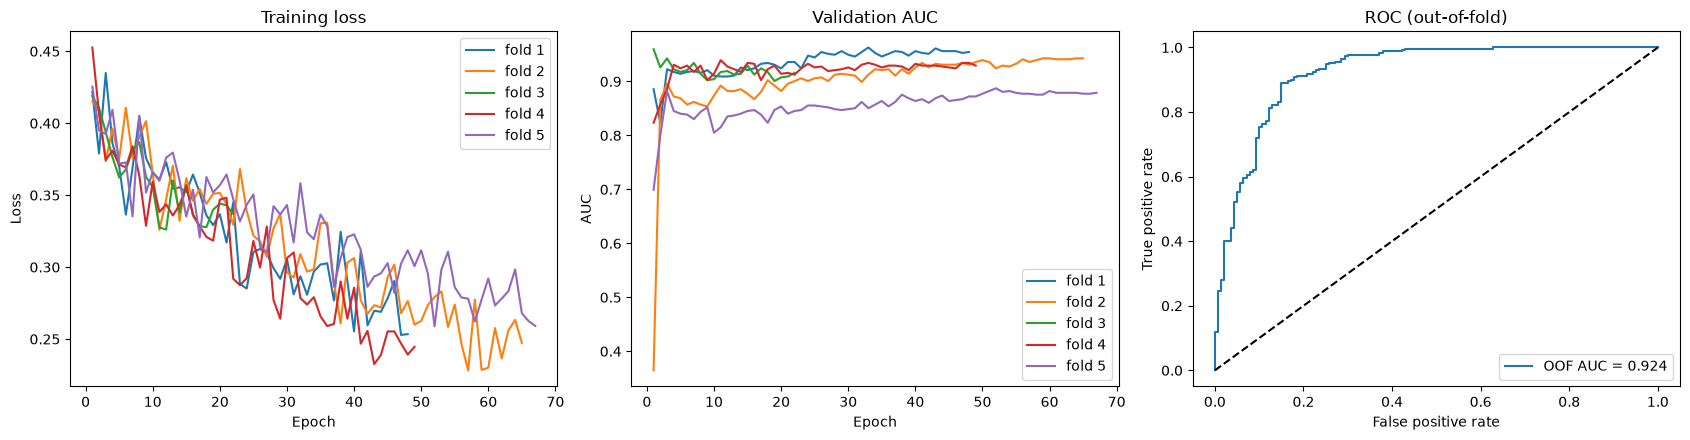

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

for f in range(1, CFG.n_folds + 1):
    h = pd.read_csv(RES_DIR / f"history_fold{f}.csv")
    ax[0].plot(h.epoch, h.train_loss, label=f"fold {f}")
    ax[1].plot(h.epoch, h.val_auc, label=f"fold {f}")
ax[0].set(title="Training loss", xlabel="Epoch", ylabel="Loss"); ax[0].legend()
ax[1].set(title="Validation AUC", xlabel="Epoch", ylabel="AUC"); ax[1].legend()

fpr, tpr, _ = roc_curve(oof_df.label, oof_df.mender_pd_score)
ax[2].plot(fpr, tpr, label=f"OOF AUC = {roc_auc_score(oof_df.label, oof_df.mender_pd_score):.3f}")
ax[2].plot([0, 1], [0, 1], "k--")
ax[2].set(title="ROC (out-of-fold)", xlabel="False positive rate", ylabel="True positive rate"); ax[2].legend()

plt.tight_layout(); plt.savefig(RES_DIR / "cv_plots.png", dpi=150); plt.show()

## 8. Predict a new mender image (ensemble of the 5 fold models)

In [19]:
def predict_mender(image_path):
    x = get_transforms(False)(Image.open(image_path).convert("L")).unsqueeze(0).to(DEVICE)
    scores = []
    for f in range(1, CFG.n_folds + 1):
        m = MenderCNN().to(DEVICE)
        m.load_state_dict(torch.load(CKPT_DIR / f"mender_cv_fold{f}.pt", map_location=DEVICE)["model"])
        m.eval()
        with torch.no_grad():
            scores.append(torch.sigmoid(m(x)).item())
    score = float(np.mean(scores))
    thr = json.load(open(RES_DIR / "threshold.json"))["threshold"]
    print("Fold scores:", [round(s, 3) for s in scores])
    print(f"Mender PD score: {score:.4f} -> {'Parkinson' if score >= thr else 'Healthy'}")
    return score

# Example (change the path):
# predict_mender("Mender/MenderPatients/your_image.png")